# Lab 6, Task 1B: Receiver Diversity

Compare selection combining, equal-gain combining, and maximum-ratio combining for QPSK over Rayleigh fading.

In [5]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Image

def find_lab_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "support" / "lab6_dsp.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the Lab 6 folder tree")

LAB_ROOT = find_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
import lab6_dsp as lab
import lab6_tools as tools
print("Lab folder:", LAB_ROOT.name)


Lab folder: Lab6


## Diversity simulation

The library supplies channel generation, error counting, and plotting. Set the branch counts and SNR grid.

In [6]:
branch_counts = (1, 2, 3, 4)
snr_db = (0, 21, 4)
results = lab.simulate_diversity(snr_db, branch_counts=tuple(branch_counts), bits_per_point=240000, seed=7602)
for method in ('sc','egc','mrc'):
    print(method.upper(), 'L=4 BER:', results['ber'][method][-1])

SC L=4 BER: [0.09777917 0.         0.029375  ]
EGC L=4 BER: [0.05272083 0.         0.010425  ]
MRC L=4 BER: [0.040475   0.         0.00686667]


## Implement the three combiners

For each symbol, `r` and `h` have shape `(L, N)`. Use the equations in the manual. Normalize each result so the desired QPSK symbol has unit gain.

In [7]:
rng = np.random.default_rng(66)
symbols = lab.qpsk_map(rng.integers(0,2,2000,dtype=np.uint8))
h = (rng.standard_normal((4,symbols.size))+1j*rng.standard_normal((4,symbols.size)))/np.sqrt(2)
r = h*symbols[None,:] + 0.08*(rng.standard_normal(h.shape)+1j*rng.standard_normal(h.shape))/np.sqrt(2)

best = np.argmax(np.abs(h)**2, axis=0)
sc = r[best, np.arange(r.shape[1])] / np.maximum(np.abs(h[best, np.arange(r.shape[1])])**2, 1e-12) * np.conj(h[best, np.arange(r.shape[1])])
egc_weights = np.conj(h) / np.maximum(np.abs(h), 1e-12)
egc = np.sum(egc_weights * r, axis=0) / np.maximum(np.sum(np.abs(h), axis=0), 1e-12)
mrc = np.sum(np.conj(h) * r, axis=0) / np.maximum(np.sum(np.abs(h)**2, axis=0), 1e-12)
print('Bit errors:', {name:int(np.count_nonzero(lab.qpsk_detect(z)!=lab.qpsk_detect(symbols))) for name,z in {'SC':sc,'EGC':egc,'MRC':mrc}.items()})

Bit errors: {'SC': 0, 'EGC': 0, 'MRC': 0}


## Expected plots

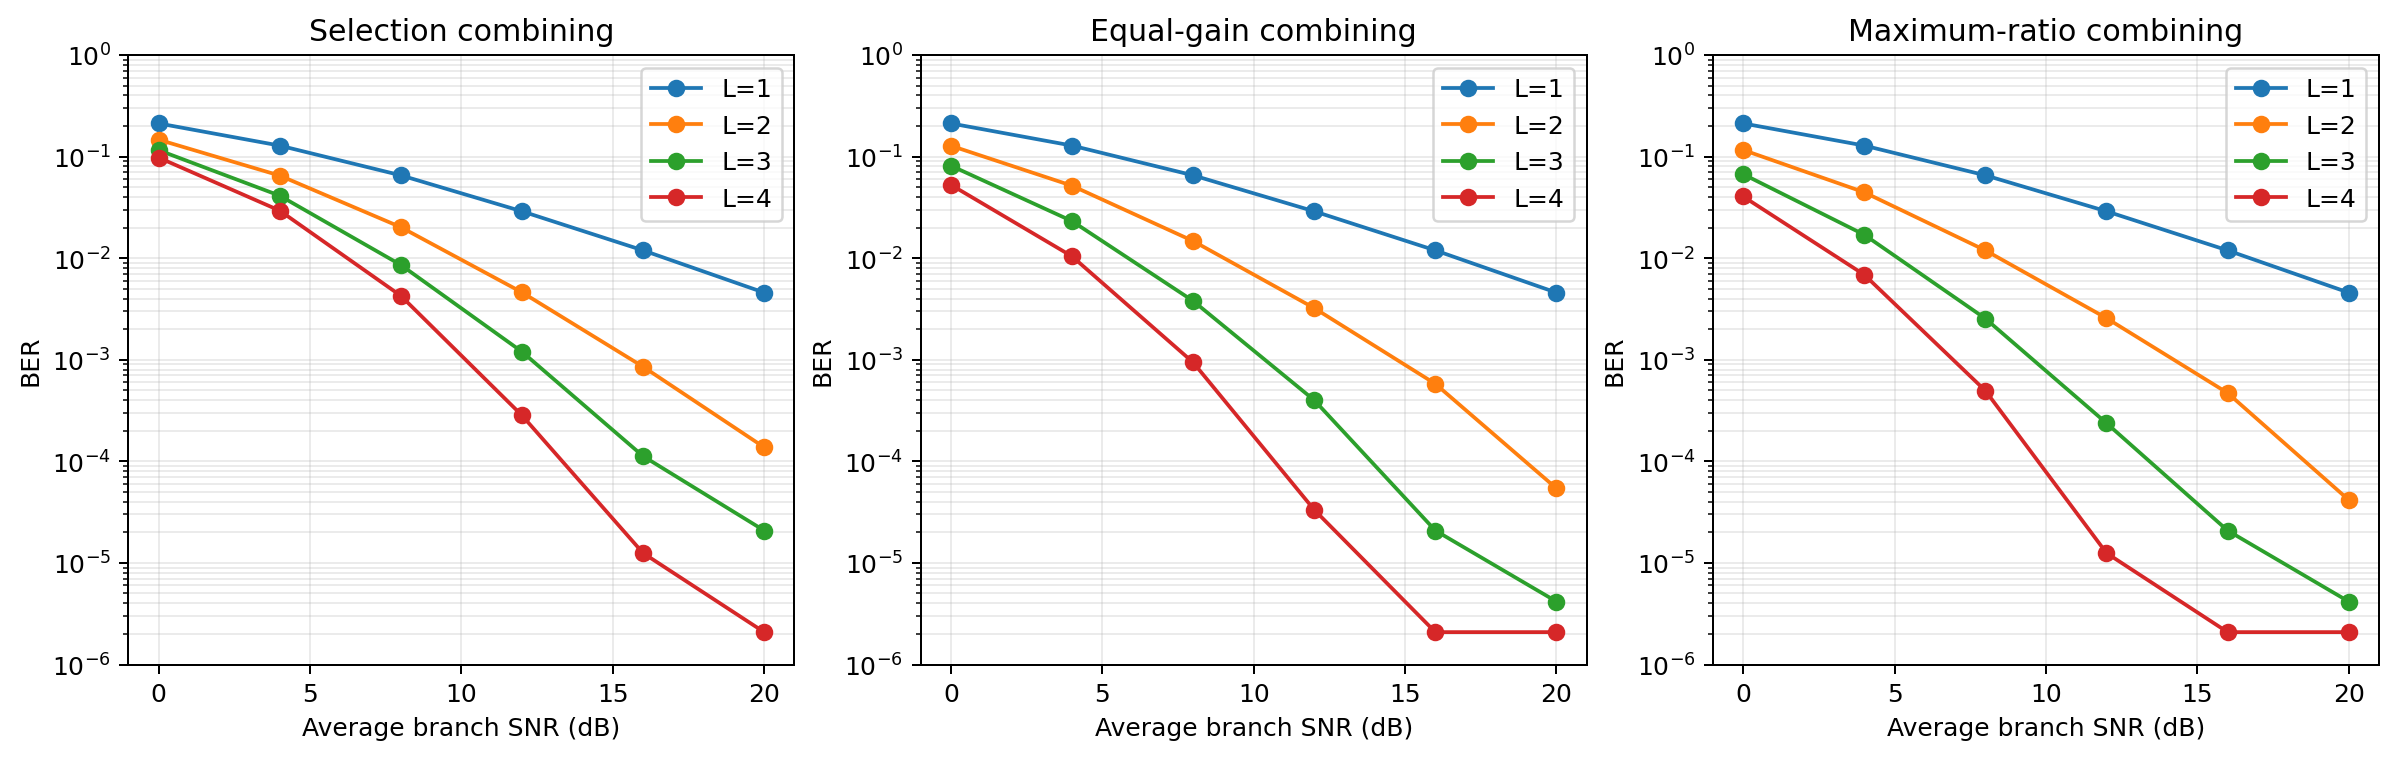

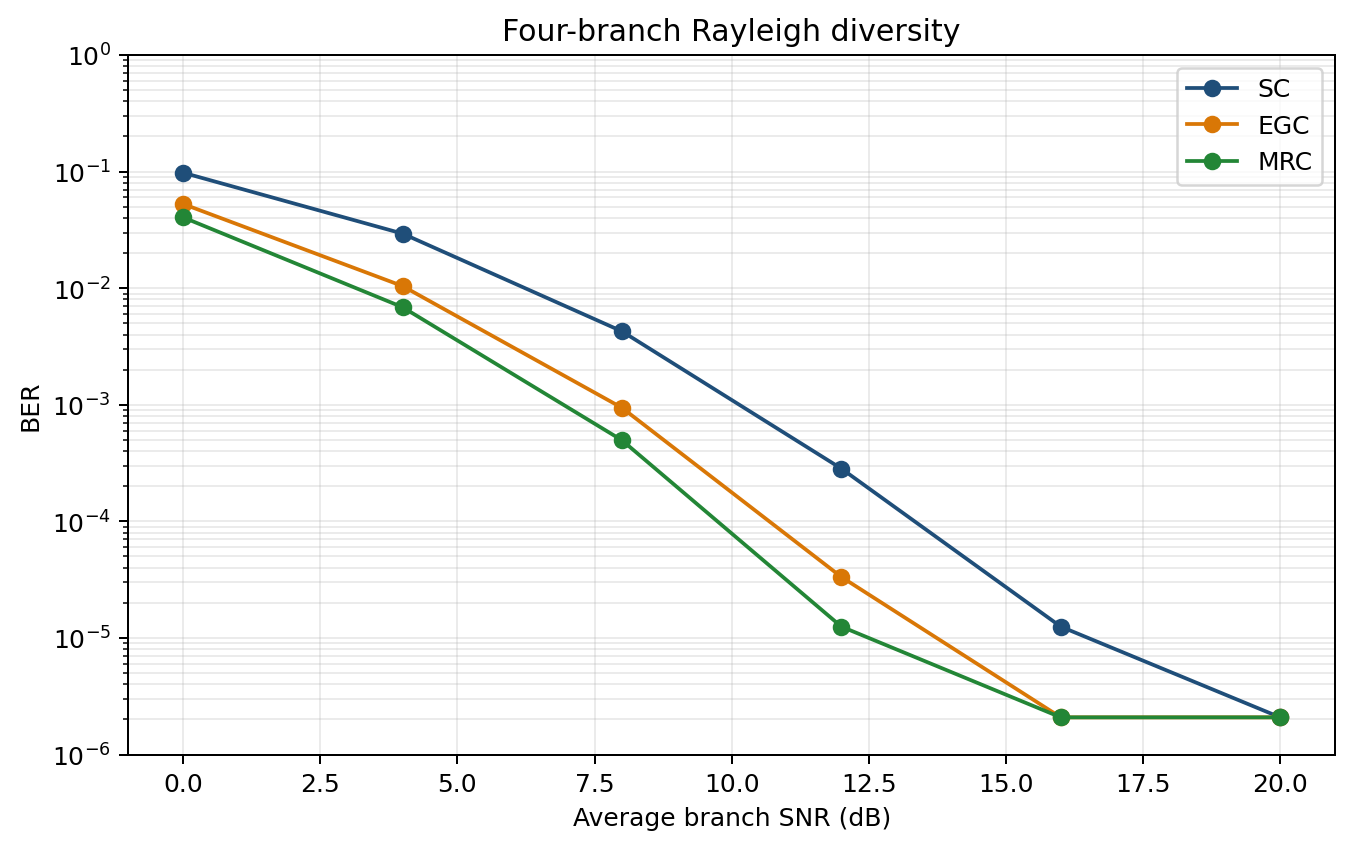

In [8]:
display(Image(filename=str(LAB_ROOT/'expected_figures/task1_diversity_by_method.png'), width=1000))
display(Image(filename=str(LAB_ROOT/'expected_figures/task1_diversity_comparison.png'), width=700))

<span style='color:#1464b4'><b>Report:</b> Compare BER as a function of SNR and branch count. </span>

As **SNR** increases, BER decreases for all three combining methods because the received signal becomes stronger relative to the noise. This trend is evident in all BER curves, which consistently decrease as average branch SNR increases. As a result, symbol detection becomes more reliable and fewer bit errors occur.

As the **branch count** increases from L=1 to L=4, BER decreases significantly for each combining method. Additional branches provide more independent fading paths, increasing diversity gain and reducing the probability that all received signals experience deep fades simultaneously.

<span style='color:#1464b4'><b>Report:</b> Compare branch count, BER, channel-knowledge requirements, and computational cost for SC, EGC, and MRC. Explain the performance and complexity tradeoff.</span>

SC, EGC, and MRC all benefit from a higher **branch count**, but they use the available diversity differently. SC only selects the strongest branch and ignores the others, so it achieves the highest **BER** of the three methods. EGC combines all branches after phase alignment, reducing BER by making use of all received signals. MRC further improves performance by weighting each branch according to its channel strength, giving more emphasis to higher-quality signals and achieving the lowest BER.

The **channel-knowledge** requirements increase from SC to EGC to MRC. SC only requires knowledge of the channel magnitude to identify the strongest branch. EGC requires channel phase information so that all branches can be coherently aligned before combining, which requires additional per-branch processing. MRC requires both channel magnitude and phase information because it must determine the proper weighting and phase correction for every branch.

The **computational cost** follows the same trend as **performance**. SC has the lowest complexity because it only compares branch magnitudes and performs detection on a single branch. EGC is more complex because each branch must be phase-corrected and summed. MRC has the highest complexity because each branch must be phase-corrected, weighted by its magnitude, and then combined. The additional channel estimation and processing required by MRC provide the best BER performance, illustrating the tradeoff between complexity and error-rate performance.